# Insert throughput on Zipf-distributed data

`bm_insert` inserts uniformly distributed values, so nearly every value is distinct. `bm_insert_zipf` inserts Zipf(1.0) distributed values (`GetZipfData` in `include/data.hpp`): the most frequent value makes up about 7% of the stream and about 217K of the 1M values are distinct. This notebook puts both next to each other for every sketch implementation.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
from IPython.display import Markdown

pd.set_option("display.max_colwidth", None)
pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update({"font.size": 10.0 * 1.3})

# Directory with bm_insert.json and bm_insert_zipf.json, see analysis.ipynb.
RESULTS_DIR = "results/gcc16_xeon8259cl"
FIGURES_DIR = "figures" if RESULTS_DIR == "results" else "figures/" + os.path.basename(RESULTS_DIR)
os.makedirs(FIGURES_DIR, exist_ok=True)

In [2]:
def si_format(x, pos):
    return (
        f"{x * 1e-9:1.0f}G"
        if x >= 1e9
        else (
            f"{x * 1e-6:1.0f}M"
            if x >= 1e6
            else f"{x * 1e-3:1.0f}K" if x >= 1e3 else f"{x:1.0f}"
        )
    )


si_formatter = matplotlib.ticker.FuncFormatter(si_format)

NAMESPACE_MAPS = {
    "CountSketch": {
        "datasketches": "DataSketches",
        "naive": "Naïve",
        "fastrange": "Fastrange",
        "fixed_size": "Fixed Size",
        "final_no_murmur_unroll": "Single Hash",
        "final": "Single Hash \\w Hash Unroll",
    },
    "SpaceSaving": {
        "datasketches": "DataSketches",
        "naive": "Naïve",
        "map": "Map",
        "heap": "Heap",
        "final": "SIMD",
        "fingerprint": "Fingerprints, No Heap",
    },
    "KarninLangLiberty": {
        "datasketches": "DataSketches",
        "naive": "Naïve",
        "no_min_max": "No Min Max",
        "no_self_move_protection": "Branching Optimization",
        "cached_level_capacities": "Level Capacity Caching",
        "pcg_random": "Fast PCG Random",
        "final": "Fixed Size",
        "branchless": "Branchless Sort & Merge",
    },
}
TYPE_ORDER = ["int16_t", "int32_t", "int64_t", "int128_t", "float", "double", "string"]

In [3]:
def load_insert_benchmark(path: str, distribution: str) -> pd.DataFrame:
    with open(path) as file:
        data = json.load(file)
    df = pd.json_normalize(data, record_path="benchmarks")
    df[["namespace", "sketch", "data_type"]] = df["name"].str.extract(
        r"BM_Insert(?:Zipf)?<(\w+)::(\w+)<([:\w]+)>"
    )
    df["sketch"] = df["sketch"].str.replace("CountMinSketch", "CountSketch")
    df["data_type"] = df["data_type"].str.replace("std::", "").str.replace("__", "")
    df["distribution"] = distribution
    return df[["sketch", "namespace", "data_type", "distribution", "items_per_second"]]


df = pd.concat(
    [
        load_insert_benchmark(f"{RESULTS_DIR}/bm_insert.json", "uniform"),
        load_insert_benchmark(f"{RESULTS_DIR}/bm_insert_zipf.json", "zipf"),
    ]
)
df

,sketch,namespace,data_type,distribution,items_per_second
0,SpaceSaving,datasketches,int16_t,uniform,"35,631,903.30"
1,SpaceSaving,datasketches,int32_t,uniform,"33,676,841.11"
2,SpaceSaving,datasketches,int64_t,uniform,"32,124,123.68"
3,SpaceSaving,datasketches,int128_t,uniform,"35,508,388.91"
4,SpaceSaving,datasketches,float,uniform,"24,682,758.74"
...,...,...,...,...,...
135,KarninLangLiberty,branchless,int64_t,zipf,"59,089,991.09"
136,KarninLangLiberty,branchless,int128_t,zipf,"28,513,880.06"
137,KarninLangLiberty,branchless,float,zipf,"54,722,134.56"
138,KarninLangLiberty,branchless,double,zipf,"55,350,933.40"


In [4]:
for sketch, data in df.groupby("sketch", sort=False):
    display(Markdown(f"## {sketch}"))
    namespaces = list(dict.fromkeys(data["namespace"]))  # benchmark order
    columns = pd.MultiIndex.from_product(
        [TYPE_ORDER, ["uniform", "zipf"]], names=["data_type", "distribution"]
    )
    rate = data.pivot_table(
        index="namespace", columns=["data_type", "distribution"], values="items_per_second"
    ).reindex(index=namespaces, columns=columns)
    display(Markdown("items/s"))
    display(rate)
    display(Markdown("Zipf / uniform"))
    display(rate.xs("zipf", axis=1, level=1) / rate.xs("uniform", axis=1, level=1))
    display(Markdown("Speedup over `final`"))
    display(rate / rate.loc["final"])

## SpaceSaving

items/s

data_type           int16_t                      int32_t                \
distribution        uniform          zipf        uniform          zipf   
namespace                                                                
datasketches  35,631,903.30 31,544,257.74  33,676,841.11 29,290,082.69   
naive         11,961,584.46 15,434,088.18  13,281,870.98 13,888,691.70   
map            4,165,284.69  5,791,234.57   4,167,777.87  5,218,995.16   
heap          41,801,772.91 28,085,946.10  48,966,698.02 28,111,535.80   
final         55,860,004.19 42,981,924.15  37,825,975.85 36,091,036.14   
fingerprint  186,458,890.71 85,010,293.12 164,946,946.78 89,486,206.33   

data_type           int64_t                     int128_t                \
distribution        uniform          zipf        uniform          zipf   
namespace                                                                
datasketches  32,124,123.68 29,883,514.50  35,508,388.91 28,506,181.78   
naive         11,665,734.09 14,301,231.55   7,448,156.01 10,405,478.70   
map            4,193,732.81  5,238,447.66   4,116,222.07  5,214,099.26   
heap          37,233,244.59 27,126,315.07  14,999,257.25 12,010,666.95   
final         31,255,923.68 30,904,996.55  27,613,321.07 24,165,613.12   
fingerprint  156,676,310.58 89,813,419.54 147,422,782.89 85,743,442.73   

data_type             float                       double                \
distribution        uniform          zipf        uniform          zipf   
namespace                                                                
datasketches  24,682,758.74 23,473,444.58  28,086,383.64 26,192,042.62   
naive         12,848,338.28 13,622,163.81  10,761,180.13 13,219,159.91   
map            3,506,501.27  4,372,210.09   3,559,878.03  4,500,888.81   
heap          49,961,659.33 27,549,749.99  30,550,999.20 24,669,651.98   
final         33,893,896.60 32,376,697.87  28,281,223.03 27,048,475.48   
fingerprint  163,141,433.53 89,389,025.38 168,171,363.55 96,771,834.01   

data_type           string                
distribution       uniform          zipf  
namespace                                 
datasketches  6,040,734.07  5,804,126.10  
naive         3,048,598.23  1,229,581.03  
map           2,587,023.90  3,192,315.96  
heap          2,123,697.09  1,041,553.49  
final         8,399,387.37  8,536,212.29  
fingerprint  20,047,229.15 19,701,801.63

Zipf / uniform

data_type,int16_t,int32_t,int64_t,int128_t,float,double,string
namespace,,,,,,,
datasketches,0.89,0.87,0.93,0.80,0.95,0.93,0.96
naive,1.29,1.05,1.23,1.40,1.06,1.23,0.40
map,1.39,1.25,1.25,1.27,1.25,1.26,1.23
heap,0.67,0.57,0.73,0.80,0.55,0.81,0.49
final,0.77,0.95,0.99,0.88,0.96,0.96,1.02
fingerprint,0.46,0.54,0.57,0.58,0.55,0.58,0.98


Speedup over `final`

... (11 outputs left out)

Zipf / uniform

data_type,int16_t,int32_t,int64_t,int128_t,float,double,string
namespace,,,,,,,
naive,1.00,1.00,1.00,1.00,1.00,1.00,1.00
datasketches,0.92,1.00,1.06,0.96,1.06,1.06,0.76
no_min_max,1.02,1.07,1.04,1.00,0.93,1.08,0.80
no_self_move_protection,0.99,1.05,1.01,1.04,0.99,1.02,0.80
cached_level_capacities,0.93,1.04,0.93,1.02,0.96,1.00,0.81
pcg_random,1.05,0.98,1.03,0.90,0.98,1.00,0.78
final,1.02,1.02,0.98,0.95,1.05,1.08,0.79
branchless,0.98,1.02,1.04,1.02,1.00,1.01,0.75


Speedup over `final`

data_type               int16_t      int32_t      int64_t      int128_t       \
distribution            uniform zipf uniform zipf uniform zipf  uniform zipf   
namespace                                                                      
naive                      0.01 0.01    0.01 0.01    0.01 0.01     0.01 0.01   
datasketches               0.82 0.74    0.77 0.76    0.73 0.79     0.77 0.78   
no_min_max                 0.82 0.82    0.77 0.81    0.75 0.80     0.77 0.81   
no_self_move_protection    0.83 0.80    0.82 0.85    0.81 0.83     0.80 0.88   
cached_level_capacities    0.95 0.86    0.87 0.89    0.91 0.87     0.85 0.91   
pcg_random                 1.03 1.06    1.03 0.99    0.98 1.03     1.06 1.00   
final                      1.00 1.00    1.00 1.00    1.00 1.00     1.00 1.00   
branchless                 1.73 1.64    1.86 1.86    1.76 1.86     0.96 1.02   

data_type                 float       double       string       
distribution            uniform zipf uniform zipf uniform zipf  
namespace                                                       
naive                      0.01 0.01    0.01 0.01    0.03 0.04  
datasketches               0.78 0.78    0.76 0.75    0.85 0.83  
no_min_max                 0.84 0.74    0.78 0.77    0.88 0.90  
no_self_move_protection    0.81 0.76    0.80 0.75    0.89 0.90  
cached_level_capacities    0.89 0.81    0.88 0.81    0.90 0.92  
pcg_random                 1.02 0.94    1.00 0.93    1.00 1.00  
final                      1.00 1.00    1.00 1.00    1.00 1.00  
branchless                 1.84 1.74    1.84 1.73    1.21 1.15

## SpaceSaving, Zipf data

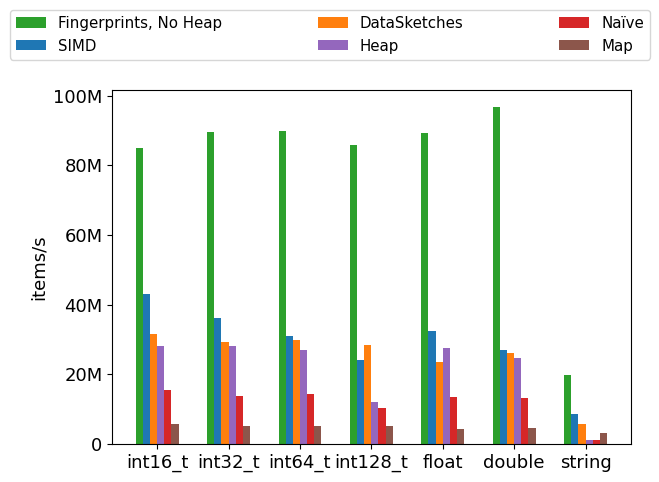

## CountSketch, Zipf data

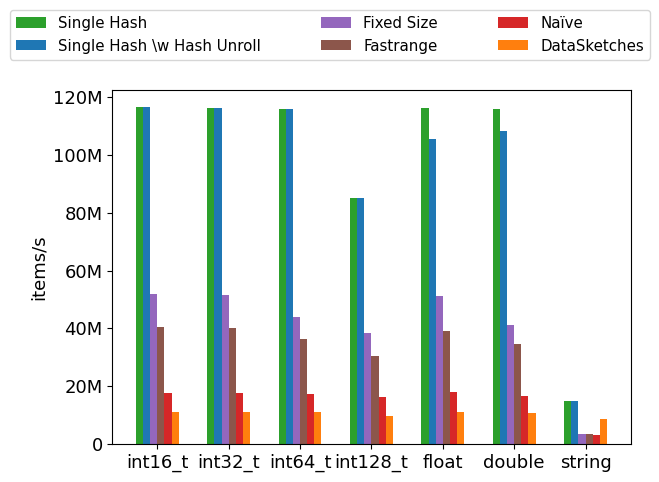

## KarninLangLiberty, Zipf data

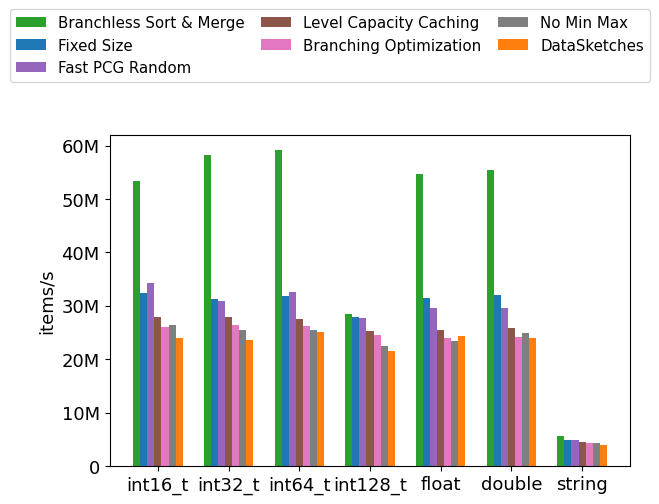

In [5]:
zipf = df[df["distribution"] == "zipf"]
for sketch, data in zipf.groupby("sketch", sort=False):
    display(Markdown(f"## {sketch}, Zipf data"))
    if sketch == "KarninLangLiberty":
        data = data[data["namespace"] != "naive"]  # as in analysis.ipynb
    data_types = [t for t in TYPE_ORDER if t in set(data["data_type"])]
    namespaces = data.groupby("namespace")["items_per_second"].mean().sort_values(ascending=False).index
    rate = data.pivot(index="namespace", columns="data_type", values="items_per_second")
    color_map = {"final": "C0", "naive": "C3", "datasketches": "C1"}
    free_colors = (f"C{i}" for i in range(10) if f"C{i}" not in color_map.values())
    fig, ax = plt.subplots()
    x = np.arange(len(data_types))
    width = 0.1
    for i, namespace in enumerate(namespaces):
        color = color_map.get(namespace) or next(free_colors)
        color_map[namespace] = color
        ax.bar(
            x + (i - (len(namespaces) - 1) / 2) * width,
            rate.loc[namespace, data_types],
            width,
            label=NAMESPACE_MAPS[sketch].get(namespace, namespace),
            color=color,
        )
    ax.set_ylabel("items/s")
    ax.set_xticks(x)
    ax.set_xticklabels(data_types)
    ax.yaxis.set_major_formatter(si_formatter)
    ax.legend(
        bbox_to_anchor=(0, 0.9, 1, 0),
        loc="lower left",
        mode="expand",
        borderaxespad=0,
        ncol=3,
        fontsize="small",
        bbox_transform=fig.transFigure,
    )
    fig.tight_layout()
    display(fig)
    fig.savefig(f"{FIGURES_DIR}/{sketch}_insert_zipf.pdf", bbox_inches="tight", pad_inches=0, dpi=300)
    plt.close(fig)